In [1]:
# imports
import pandas as pd                              # it's pandas
import Constants as c                           # constants
import Functions as f                           # plotting functions
import matplotlib.pyplot as plt
import numpy as np
import plotly.offline as po
import pickle
from math import radians
from scipy.stats import gaussian_kde, weibull_min
from random import randint
from scipy.optimize import curve_fit
import plotly.express as px
import plotly.graph_objects as go
import plotly.offline as pyo


In [2]:
# Import dataframe from "out" folder
with open('../../out/TREAD_out.pkl', 'rb') as file:
    df, trips_list, name_of_route = pickle.load(file)
# pick one random trip to fiddle with it
#sample_trip = trips_list[73]
sample_trip = trips_list[1]
display(f"There are in total {df['trip_id'].max()} separate trips and {df['Route'].unique().shape[0]} total routes")

'There are in total 35731 separate trips and 910 total routes'

In [3]:
# some info about the dataframe
sample_trip.reset_index(inplace=True, drop=True)
# the above instruction sometimes adds a new column called 'index', which is subsequently removed
if 'index' in sample_trip.columns:
    print("Column \"Index\" removed")
    sample_trip.drop(['index'], axis=1, inplace=True)
display(sample_trip.head(3))
#display(df)
# current columns (aka features) of the dataset
print(df.columns)
display(df.info())

,MMSI,BaseDateTime,LAT,LON,SOG,COG,Heading,VesselName,VesselType,Status,...,Draft,IsClassA,Avg_Speed,EstimatedStatus,IsInWP,IsInSignificantWP,Route,IsInRoute,group,trip_id
0,303174000,2019-02-20 18:55:58,21.3100,-157.8744,7.5,124.9,511.0,GAIL ANN,30,99,...,NaN,False,3.98,sailing,WP_135,<NA>,WP_135 - WP_118,True,1,1035
1,303174000,2019-02-20 18:56:59,21.3086,-157.8727,7.6,135.1,511.0,GAIL ANN,30,99,...,NaN,False,7.50,sailing,WP_135,<NA>,WP_135 - WP_118,True,0,1035
2,303174000,2019-02-20 18:59:33,21.3042,-157.8693,7.6,149.9,511.0,GAIL ANN,30,99,...,NaN,False,7.62,sailing,WP_135,<NA>,WP_135 - WP_118,True,0,1035


Index(['MMSI', 'BaseDateTime', 'LAT', 'LON', 'SOG', 'COG', 'Heading',
       'VesselName', 'VesselType', 'Status', 'Length', 'Width', 'Draft',
       'IsClassA', 'Avg_Speed', 'EstimatedStatus', 'IsInWP',
       'IsInSignificantWP', 'Route', 'IsInRoute', 'trip_id'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
Index: 5415129 entries, 0 to 2371
Data columns (total 21 columns):
 #   Column             Dtype        
---  ------             -----        
 0   MMSI               int32        
 1   BaseDateTime       datetime64[s]
 2   LAT                float64      
 3   LON                float64      
 4   SOG                float64      
 5   COG                float64      
 6   Heading            float64      
 7   VesselName         string       
 8   VesselType         int16        
 9   Status             int8         
 10  Length             int16        
 11  Width              int16        
 12  Draft              float32      
 13  IsClassA           bool         

None

#### General Approach
1. Normalization (some features have different scales) (to be decided, probably not)
2. Features selection
3. Algorithm

In [4]:
# check which columns contain any null values
df.isnull().sum()

MMSI                       0
BaseDateTime               0
LAT                        0
LON                        0
SOG                        0
COG                        0
Heading                    0
VesselName            449842
VesselType                 0
Status                     0
Length                     0
Width                      0
Draft                3582281
IsClassA                   0
Avg_Speed                  0
EstimatedStatus            0
IsInWP               1173087
IsInSignificantWP    1624548
Route                      0
IsInRoute                  0
trip_id                    0
dtype: int64

In [5]:
# all the trips of the chosen route are separated in a list
# create a single dataframe with all of them together
#myDF = pd.concat(trips_list, ignore_index=True, axis=0)
#myDF = pd.concat([myDF, df[df['Route'] == 'WP_61' + ' - ' + 'WP_96']], axis=0)
#myDF = pd.concat([myDF, df[df['Route'] == 'WP_96' + ' - ' + 'WP_61']], axis=0)
# the route name is the one chosen in TREAD.ipynb and saved inside the pickle file
myDF = df[df['Route'] == name_of_route].copy()
# trip_id is a nullable Int64 (from TREAD's cumsum): together with datetime columns in hover_data it makes plotly fail
myDF['trip_id'] = myDF['trip_id'].astype('int64')

,trip_id,count
0,30627,524
1,10279,294
2,16616,267
3,16546,267
4,24701,233
...,...,...
179,21732,64
180,23892,64
181,24357,59
182,10288,55


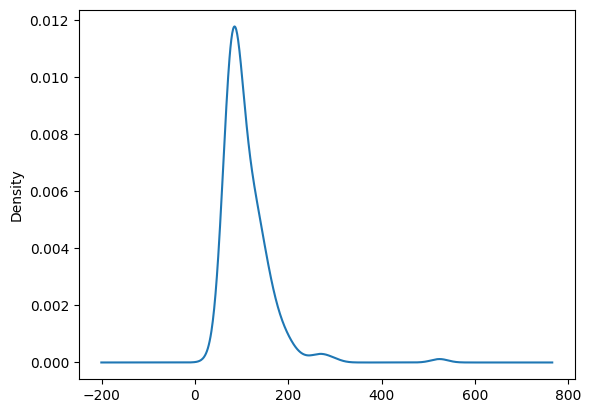

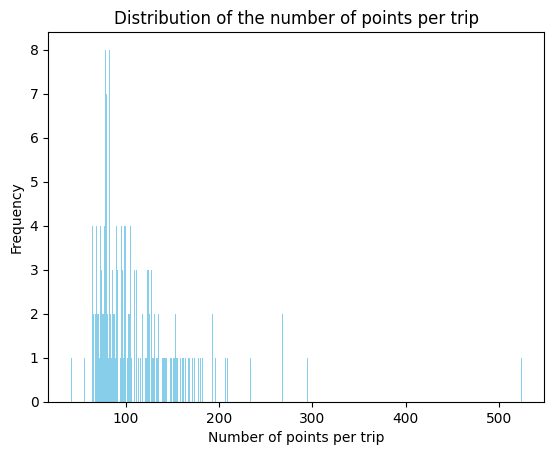

In [6]:
# for each trip_id, extract how many points where generated
points_per_trip = myDF['trip_id'].value_counts().reset_index(name='count')

display(points_per_trip)

# plot the kde approximation of the distribution of the amount of points per trip
points_per_trip["count"].plot(kind="kde")
# plot a more precise histogram of the same distribution
plt.figure()
plt.hist(points_per_trip['count'], 
         bins=range(min(points_per_trip['count']), max(points_per_trip['count']) + 1, 1), # from, to, step
         color='skyblue')
plt.xlabel('Number of points per trip')
plt.ylabel('Frequency')
plt.title('Distribution of the number of points per trip')
plt.show()

In [7]:
# Calculate x and y components of speed starting from known values of SOG and COG
# System of equations (as written in the paper): 1) SOG^2 = Vx^2 + Vy^2, 2) COG = arctan((Vy)/(Vx))
# For equation #2, there is an issue as arctan is hard to invert. So instead of using this system of equations, we can use another one:
# New system of equations: 1) Vx = SOG * cos(COG), 2) Vy = SOG * sin(COG)

# First step: convert true north COG angles into standard arithmetic angles.
# Formula: X = (450 - COG) mod 360 
# https://community.safe.com/general-10/how-to-convert-arithmetic-angles-to-geographic-angles-18164

myDF['A_COG'] = (450 - myDF['COG']) % 360
display(myDF['A_COG'].head(3))
# convert the arithmetic angles in radians
myDF['A_COG'] = myDF['A_COG'].apply(radians)
display(myDF['A_COG'].head(3))
# calculate Vx and Vy
myDF['V_x'] = myDF['SOG'] * np.cos(myDF['A_COG'])
myDF['V_y'] = myDF['SOG'] * np.sin(myDF['A_COG'])
display(myDF[['V_x', 'V_y']].head(3))

# optional: compare with points on map:
#plot = f.route_arrows_plot(inputDF=myDF.head(3).copy(), color_criteria='Avg_Speed', scale_factor=0.0001)
#po.plot(plot, auto_open=True)

3392    113.0
3393     20.0
3394    252.0
Name: A_COG, dtype: float64

3392    1.972222
3393    0.349066
3394    4.398230
Name: A_COG, dtype: float64

,V_x,V_y
3392,-0.547024,1.288707
3393,0.751754,0.273616
3394,-0.679837,-2.092324


In [8]:
# Divide the dataset in train and test

# Select supposedly good trips to use as "normal" behaviour -> train dataset
points_per_trip.sort_values(by="count", ascending=True, inplace=True)

# Supposedly Good Trips (save the IDs)
train_ids = pd.Series(name="trip_id") # new empty Series
# coefficient used to separate train dataset from test dataset
GT_COEFF = 1 # G.T. = "Good Trips"
# Fill the Series with the "trip_id" of the first (GT_COEFF)% of trips (ordered from shortest to longest)
train_ids = points_per_trip.iloc[0:int(len(points_per_trip) * GT_COEFF), 0]
test_ids = set(points_per_trip["trip_id"]).difference(train_ids)

try: # quick check
    assert len(train_ids) + len(test_ids) == len(points_per_trip)
except AssertionError:
    print(f"Error: {len(train_ids)} + {len(test_ids)} should be equal to {len(points_per_trip)}. Values not matching")

# Create a new DF with the full data of the selected trips
train_DF = myDF[myDF['trip_id'].isin(train_ids)]
test_DF = myDF[myDF['trip_id'].isin(test_ids)]

#final_DF = 

# quick check: from a groupby (on trip_id) of train_df I expect the number of rows to be equal to the len of train_ids
test_delete = train_DF.groupby(by="trip_id")
try:
    assert len(train_ids) == len(test_delete), "Should be the same length"
except AssertionError:
    print(f"Error: {len(train_ids)} should be equal to {len(test_delete)}. Values not matching")
del test_delete

# no title: the plot is used in the thesis, where the caption describes it
plot = f.route_arrows_plot(inputDF=train_DF, color_criteria='Avg_Speed', scale_factor=0.0001)
f._save_map(plot, 'selected_trips.html') # with the scale bar

plot = f.route_arrows_plot(inputDF=test_DF, color_criteria='Avg_Speed', scale_factor=0.0001, title=f'Test dataset (coeff: {round(1-GT_COEFF, 1)}) of Route {train_DF.iloc[0, train_DF.columns.get_loc("Route")]}')
po.plot(plot, auto_open=True, filename='../../plot/non_selected_trips.html')

[route_arrows_plot] Dataset has 20241 points, sampling down to 5000 for rendering.


'../../plot/non_selected_trips.html'

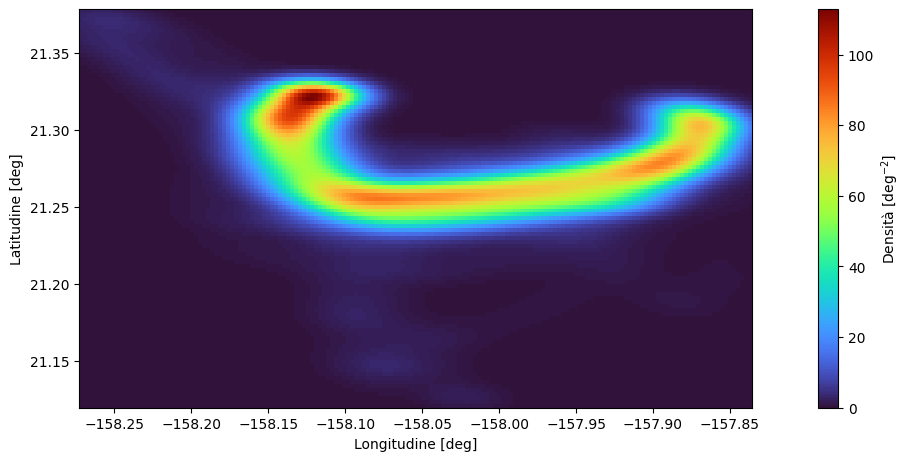

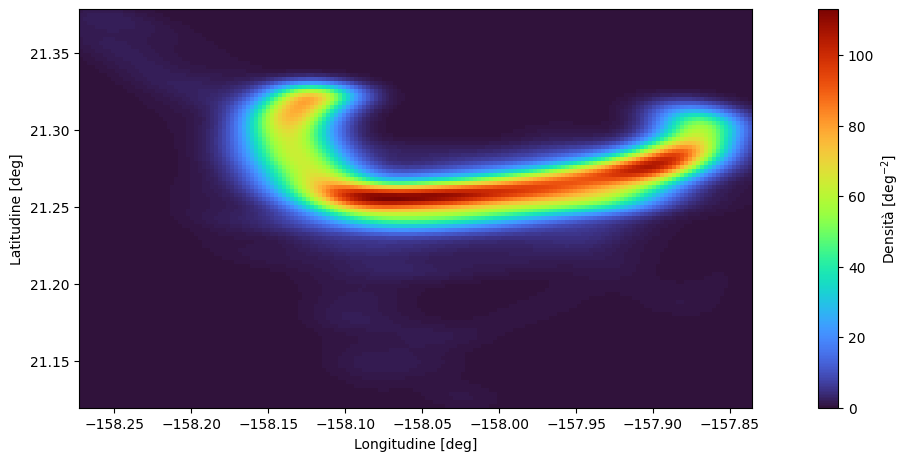

In [9]:
# Extract grid ranges
lon_min, lon_max = train_DF['LON'].min(), train_DF['LON'].max()
lat_min, lat_max = train_DF['LAT'].min(), train_DF['LAT'].max()

# keep same aspect ration
lon_range = lon_max - lon_min
lat_range = lat_max - lat_min
aspect_ratio = lon_range / lat_range

n_points = 100 
lon_points = int(n_points * aspect_ratio)
lat_points = n_points
    
# Create the actual grid
lon_grid = np.linspace(lon_min, lon_max, lon_points) # create equally spaced points from lon_min to lon_max
lat_grid = np.linspace(lat_min, lat_max, lat_points)
LON, LAT = np.meshgrid(lon_grid, lat_grid) # creates rectangular grid of points out of lon, lat values

# Calculate KDE using LAT, LON values
positions = np.vstack([LON.ravel(), LAT.ravel()])
values = np.vstack([train_DF['LON'], train_DF['LAT']])
kernel_geo = gaussian_kde(values)
Z_geo = np.reshape(kernel_geo(positions), LON.shape)

# Calculate KDE using V_x, V_y values
# Geographical coordinates are weighted using the magnitude of the vector V
values_v = np.vstack([train_DF['LON'], train_DF['LAT']])
kernel_v = gaussian_kde(values_v, weights=train_DF['SOG'])
Z_v = np.reshape(kernel_v(positions), LON.shape)

# Calculate size of the plot in order to keep the aspect ratio
base_size = 8
fig_width = base_size * aspect_ratio if aspect_ratio > 1 else base_size
fig_height = base_size / aspect_ratio if aspect_ratio > 1 else base_size
    
# Plot in separate figures
# KDE of LAT,LON values
fig = f.plot_kde(LON, LAT, Z_geo, fig_width, fig_height)

# plot KDE of speed vectors
fig = f.plot_kde(LON, LAT, Z_v, fig_width, fig_height)

plt.show()

In [10]:
# check that the integral sum is equal to one (since KDE returns a probability density)
# Calculate the area of a cell of the grid
d_lon = lon_grid[9] - lon_grid[8] # difference between two consecutive lon values
d_lat = lat_grid[9] - lat_grid[8] # difference between two consecutive lat values
dA = d_lon * d_lat # differential area dA (used to do the integration)

# Calculate integral sum for both KDEs by rows and by columns
integral_geo = np.sum(np.sum(Z_geo, axis=1), axis=0) * dA # this works because the grid is equally spaced
integral_v = np.sum(np.sum(Z_v, axis=1), axis=0) * dA # with an irregular grid "np.trapz()" should be used

# This two values below need to be very close to one, otherwise there is something wrong with the KDE
print(f"Geo KDE integral sum: {integral_geo}")
print(f"V KDE integral sum: {integral_v}")

Geo KDE integral sum: 0.993613593299308
V KDE integral sum: 0.9961262522979598


In [11]:
train_DF.reset_index(inplace=True)
display(train_DF.head(3))
#train_DF.set_index(['MMSI', 'BaseDateTime'], inplace=True)
#display(train_DF.head(3))

,index,MMSI,BaseDateTime,LAT,LON,SOG,COG,Heading,VesselName,VesselType,...,Avg_Speed,EstimatedStatus,IsInWP,IsInSignificantWP,Route,IsInRoute,trip_id,A_COG,V_x,V_y
0,3392,245011000,2019-01-07 14:44:39,21.3013,-157.8668,1.4,337.0,35.0,PRINS HENDRIK,80,...,0.83,sailing,WP_135,<NA>,WP_135 - WP_118,True,213,1.972222,-0.547024,1.288707
1,3393,245011000,2019-01-07 14:49:18,21.3032,-157.8673,0.8,70.0,169.0,PRINS HENDRIK,80,...,1.52,sailing,WP_135,<NA>,WP_135 - WP_118,True,213,0.349066,0.751754,0.273616
2,3394,245011000,2019-01-07 14:51:08,21.3028,-157.8673,2.2,198.0,197.0,PRINS HENDRIK,80,...,0.79,sailing,WP_135,<NA>,WP_135 - WP_118,True,213,4.398230,-0.679837,-2.092324


In [12]:
# Calculate product between Spatial KDE and Speed KDE (see equation 8 page 2236)
Z_product = Z_geo * Z_v

try:
    assert (Z_product.shape == Z_geo.shape) and (Z_product.shape == Z_v.shape)
    assert Z_product[0][0] == Z_geo[0][0] * Z_v[0][0]
except AssertionError:
    print("The final matrix should have the same shape of the starting matrices")

DISTANCE_PARAMETER_METERS = 500

train_DF = train_DF.copy() # this is necessary in order to remove an annoying warning (SettingWithCopyWarning)

lons = train_DF['LON'].values
lats = train_DF['LAT'].values

# For each point, save a boolean mask with True values for points that are within the distance threshold
train_DF['Points_Mask'] = pd.Series(dtype=object)

for i in range(len(train_DF)):
    lat1 = np.full_like(lats, train_DF.iloc[i, train_DF.columns.get_loc('LAT')])
    lon1 = np.full_like(lons, train_DF.iloc[i, train_DF.columns.get_loc('LON')])
    distances = f.great_circle_distance_vectorized(lon_left=lon1,
                                                   lat_left=lat1,
                                                   lon_right=lons,
                                                   lat_right=lats)
    boolean_mask = (distances < DISTANCE_PARAMETER_METERS)
    train_DF.at[i,'Points_Mask'] = boolean_mask

# test with random points

random_row_number = randint(0, len(train_DF) - 1) # randint includes both ends
chosen_mask = train_DF.loc[random_row_number, 'Points_Mask'].copy()

# red: points within DISTANCE_PARAMETER_METERS from the chosen point, grey: the others (no title: used in the thesis)
f.route_plot(inputDF=train_DF, color_criteria=chosen_mask, filename='regions_test_plot.html', selected_name="Intorno di 500m")


Gtk-Message: 00:06:15.383: Not loading module "atk-bridge": The functionality is provided by GTK natively. Please try to not load it.
Gtk-Message: 00:06:15.607: Not loading module "atk-bridge": The functionality is provided by GTK natively. Please try to not load it.


In [13]:
# Extract desity values of each point
# Two different approaches: reverse of KDE or linear interpolation

train_DF['Density'] = pd.Series(dtype=pd.Float64Dtype())

# Approach 1: parse LON,LAT values to the density kernels used before in order to get the density values in return

density_vals_geo = kernel_geo(np.array([train_DF['LON'], train_DF['LAT']]))
density_vals_V = kernel_v(np.array([train_DF['LON'], train_DF['LAT']]))
train_DF['Density'] = density_vals_geo * density_vals_V

# Approach 2: interpolate from already know density values associated to the grid used to calculate the KDE
# This works decently only if the grid has many points
from scipy.interpolate import RegularGridInterpolator

intp_fun = RegularGridInterpolator((lon_grid, lat_grid), Z_product.T)
interpolated_density_vals = intp_fun(np.column_stack((train_DF['LON'], train_DF['LAT'])))

# Check the correlation between the values calculated by reversing the KDE and the interpolated ones
display(train_DF['Density'].corr(pd.Series(interpolated_density_vals)))

# Plot the result on a map
# check: share of points with density > 1 (log > 0), so that the sum of logs grows with the number of neighbours
print(f"Points with density > 1: {(train_DF['Density'] > 1).mean():.2%}")
print(train_DF['Density'].describe())

f.route_plot(inputDF=train_DF, color_criteria=train_DF['Density'], filename='KDE_pdf.html')


np.float64(0.9998787920106269)

Points with density > 1: 99.38%
count    20241.000000
mean      4756.425850
std       2674.623417
min          0.055318
25%       2659.080266
50%       4856.299334
75%       7014.092426
max       9757.295745
Name: Density, dtype: float64


In [14]:
# Calculate production (produttoria) of values

train_DF['Density_prod'] = pd.Series(dtype=pd.Float64Dtype())
train_DF['Log_Density_prod'] = pd.Series(dtype=pd.Float64Dtype())

# test to find the row with most True values in 'Points_Mask'
train_DF['Count_Trues'] = train_DF['Points_Mask'].apply(lambda x: sum(x))
idx_max_true = train_DF['Count_Trues'].idxmax()
found_row = train_DF.loc[idx_max_true]
display(idx_max_true)
display(found_row)


# array for saving density products
density_products = np.ones(len(train_DF))
log_density_products = np.zeros(len(train_DF))

# iterate along the rows of the dataframe
for i in range(len(train_DF)):
    mask = train_DF.iloc[i]['Points_Mask']
    density_products[i] = np.prod(train_DF.loc[mask, 'Density'])
    log_density_products[i] = np.sum(np.log(train_DF.loc[mask, 'Density']))

# Save the resulting array of arrays into a column of the dataframe
train_DF['Density_prod'] = density_products
train_DF['Log_Density_prod'] = log_density_products

found_row = train_DF.loc[idx_max_true]
display(found_row)


Gtk-Message: 00:06:49.986: Not loading module "atk-bridge": The functionality is provided by GTK natively. Please try to not load it.
Gtk-Message: 00:06:59.828: Not loading module "atk-bridge": The functionality is provided by GTK natively. Please try to not load it.


11098

index                                                             2471
MMSI                                                         367310240
BaseDateTime                                       2019-01-18 21:12:10
LAT                                                            21.3236
LON                                                          -158.1179
SOG                                                                7.0
COG                                                              116.8
Heading                                                          511.0
VesselName                                                    NOHO-LOA
VesselType                                                          90
Status                                                               5
Length                                                              29
Width                                                                8
Draft                                                              NaN
IsClas

/home/accazeta/Scrivania/Unibg/ZTesi Magistrale/workspace/AIS_data_analysis/.venv/lib/python3.12/site-packages/numpy/_core/_methods.py:55: RuntimeWarning:

overflow encountered in reduce



index                                                             2471
MMSI                                                         367310240
BaseDateTime                                       2019-01-18 21:12:10
LAT                                                            21.3236
LON                                                          -158.1179
SOG                                                                7.0
COG                                                              116.8
Heading                                                          511.0
VesselName                                                    NOHO-LOA
VesselType                                                          90
Status                                                               5
Length                                                              29
Width                                                                8
Draft                                                              NaN
IsClas

In [15]:
# Calculate density products
log_density_products = np.zeros(len(train_DF))

# for each row of the dataframe
for i in range(len(train_DF)):
    mask = train_DF.iloc[i]['Points_Mask']
    # extract values that need to be multiplied
    filtered_densities = train_DF.loc[mask, 'Density']
    # calculate the sum of logaritms instead of the production
    log_density_products[i] = round(np.sum(np.log(filtered_densities)), 2)
    # inverse operation to go back to the original values:
    # density_products[i] = np.exp(log_density_products[i])

# Save the result inside the dataframe
train_DF['Log_Density_prod'] = log_density_products

# Normalization to compare relative values
# The scale goes from min_log to max_log
min_log = train_DF['Log_Density_prod'].min()
max_log = train_DF['Log_Density_prod'].max()
train_DF['Normalized_Log_Density'] = (train_DF['Log_Density_prod'] - min_log) / (max_log - min_log)

# Describe the resulting dataframe columns
print("Log density values:")
print(train_DF['Log_Density_prod'].describe())
print("Normalized Values:")
print(train_DF['Normalized_Log_Density'].describe())

f.route_plot(inputDF=train_DF, color_criteria=train_DF['Log_Density_prod'], filename='log_KDE.html')
f.route_plot(inputDF=train_DF, color_criteria=train_DF['Normalized_Log_Density'], filename='normalized_log_KDE.html')

Log density values:
count    20241.000000
mean      1953.660583
std       2075.624694
min         -6.950000
25%        648.610000
50%       1068.310000
75%       2638.270000
max       9118.060000
Name: Log_Density_prod, dtype: float64
Normalized Values:
count    20241.000000
mean         0.214861
std          0.227465
min          0.000000
25%          0.071842
50%          0.117837
75%          0.289887
max          1.000000
Name: Normalized_Log_Density, dtype: float64


#### Prediction and stuff using Weibull

Dataset size: 20241 rows
Number of unique ships (MMSI): 40
Number of unique trips: 184
Time range: 2019-01-01 18:48:54 to 2019-03-31 02:42:10

Trip statistics:
Average points per trip: 110.0
Min points per trip: 41, Max points per trip: 524

Calculating trip durations...
Check if everything works fine:
  Trip 213: start=2019-01-07 14:44:39, end=2019-01-07 17:45:28, duration=10849.0 seconds
Check if everything works fine:
  Trip 1035: start=2019-02-20 18:55:58, end=2019-02-20 21:39:59, duration=9841.0 seconds
Check if everything works fine:
  Trip 1621: start=2019-01-06 18:16:40, end=2019-01-06 21:17:01, duration=10821.0 seconds

Trip duration statistics seconds (minutes):
  Minimum: 5044.0 (84.1)
  Maximum: 39379.0 (656.3)
  Median: 8398.5 (140.0)


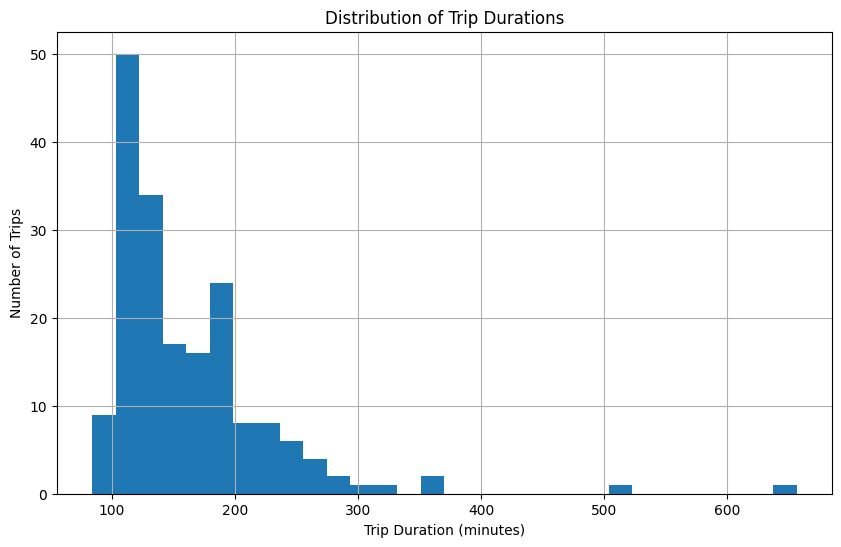

In [16]:
# Print DataFrame summary
print(f"Dataset size: {len(train_DF)} rows")
print(f"Number of unique ships (MMSI): {train_DF['MMSI'].nunique()}")
print(f"Number of unique trips: {train_DF['trip_id'].nunique()}")
print(f"Time range: {train_DF['BaseDateTime'].min()} to {train_DF['BaseDateTime'].max()}")

# Create a summary of trips
trip_counts = train_DF.groupby('trip_id').size()
print(f"\nTrip statistics:")
print(f"Average points per trip: {trip_counts.mean():.1f}")
print(f"Min points per trip: {trip_counts.min()}, Max points per trip: {trip_counts.max()}")

# Calculate trip durations based on actual timestamps
trip_durations = {}
all_trip_ids = trip_counts.index

print("\nCalculating trip durations...")
for trip_id in all_trip_ids:
    trip_data = train_DF[train_DF['trip_id'] == trip_id]
    if len(trip_data) >= c.SHORT_TRIP_THRESHOLD:
        # Get the first and last timestamp for this trip
        start_time = trip_data['BaseDateTime'].min()
        end_time = trip_data['BaseDateTime'].max()
        # Calculate duration in seconds
        duration = (end_time - start_time).total_seconds()
        trip_durations[trip_id] = duration # save the duration to a dictionary
        # Debug output for the first few trips
        if len(trip_durations) <= 3:
            print("Check if everything works fine:")
            print(f"  Trip {trip_id}: start={start_time}, end={end_time}, duration={duration:.1f} seconds")

# Calculate statistics on trip durations
durations = np.array(list(trip_durations.values())) # convert dict values to ndarray to easily calculate statistics
min_duration = np.min(durations)
max_duration = np.max(durations)
median_duration = np.median(durations)

print(f"\nTrip duration statistics seconds (minutes):")
print(f"  Minimum: {min_duration:.1f} ({min_duration/60:.1f})")
print(f"  Maximum: {max_duration:.1f} ({max_duration/60:.1f})")
print(f"  Median: {median_duration:.1f} ({median_duration/60:.1f})")

# Plot trip duration distribution
plt.figure(figsize=(10, 6))
plt.hist(durations/60, bins=30)
plt.xlabel('Trip Duration (minutes)')
plt.ylabel('Number of Trips')
plt.title('Distribution of Trip Durations')
plt.grid(True)
plt.show()

Calculate time lags (adaptively) and distance statistics for each time lag 


Adaptive time lags (seconds):
  Median lag: 965.00
  252 sec (4.2 min)
  394 sec (6.6 min)
  537 sec (8.9 min)
  680 sec (11.3 min)
  823 sec (13.7 min)
  965 sec (16.1 min)
  1108 sec (18.5 min)
  1251 sec (20.9 min)
  1394 sec (23.2 min)
  1536 sec (25.6 min)
  1679 sec (28.0 min)



Gtk-Message: 00:07:51.741: Not loading module "atk-bridge": The functionality is provided by GTK natively. Please try to not load it.
Gtk-Message: 00:07:52.249: Not loading module "atk-bridge": The functionality is provided by GTK natively. Please try to not load it.



Distance statistics for each time lag:
For lag 252s: 19528 points, average distance: 136.97 m
For lag 394s: 19304 points, average distance: 268.47 m
For lag 537s: 19028 points, average distance: 439.21 m
For lag 680s: 18737 points, average distance: 636.73 m
For lag 823s: 18452 points, average distance: 861.42 m
For lag 965s: 18178 points, average distance: 1105.64 m
For lag 1108s: 17887 points, average distance: 1371.40 m
For lag 1251s: 17601 points, average distance: 1650.93 m
For lag 1394s: 17329 points, average distance: 1953.59 m
For lag 1536s: 17030 points, average distance: 2262.26 m
For lag 1679s: 16745 points, average distance: 2585.21 m


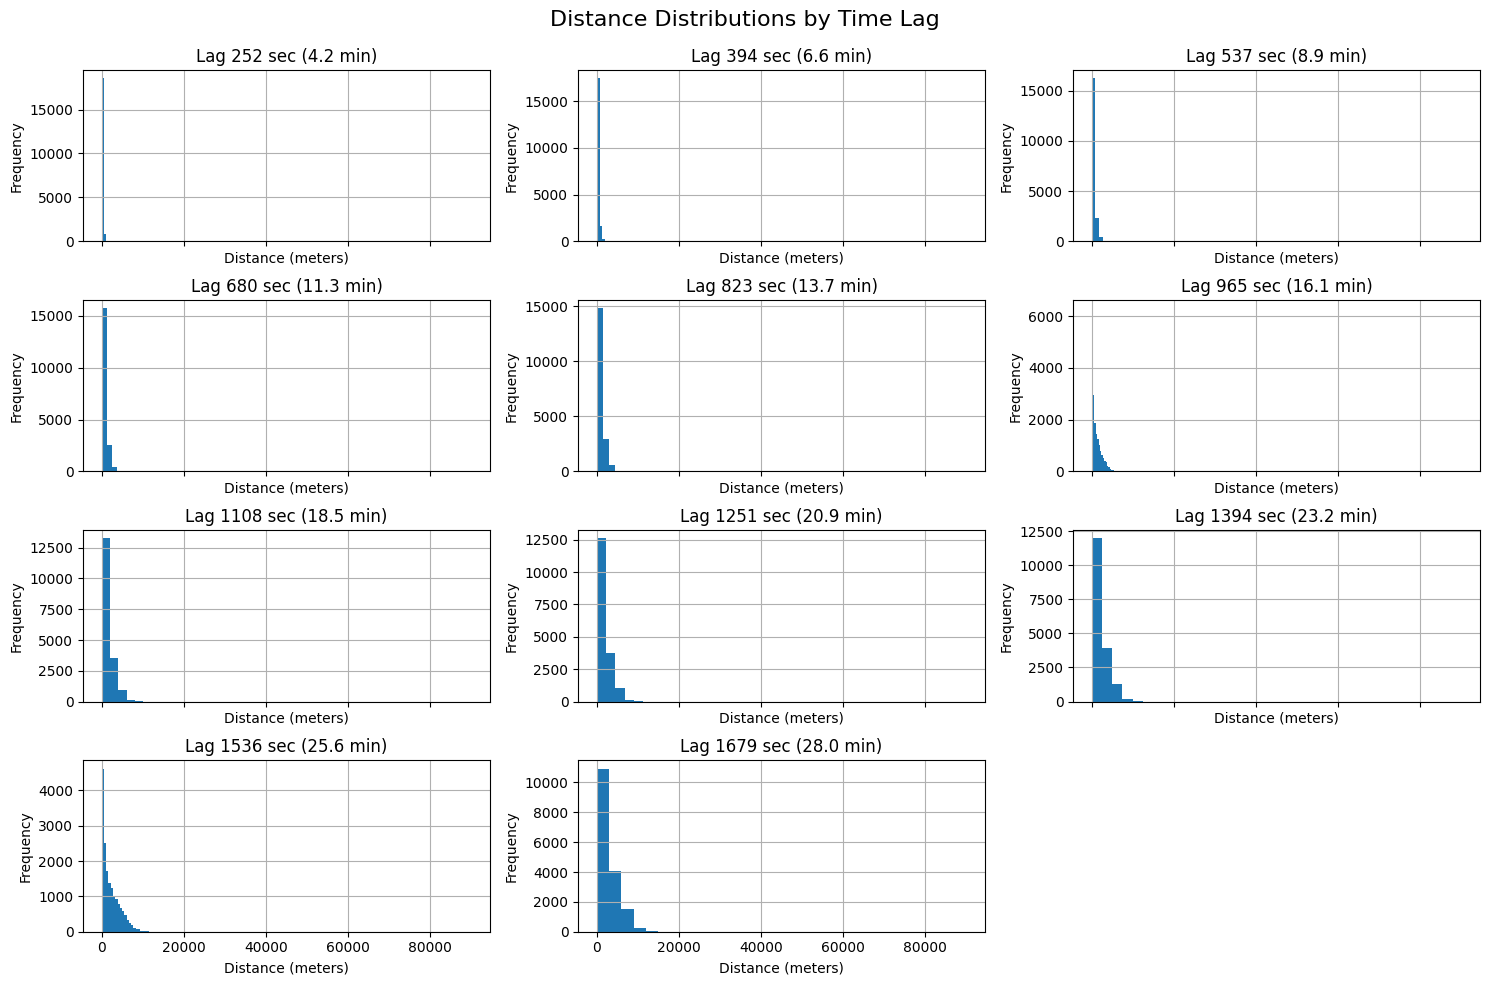

In [17]:
# Determine adaptive time lags based on dataset
# For short trips, use smaller time lags
#----------CHECK-----------------
# The minimum should be the AIS refresh rate in the area?
min_lag = max(30, min_duration / 20)  # At least 30 seconds or 1/20 of shortest trip
max_lag = min(median_duration / 5, 3600)  # At most 1/5 of median trip or 1 hour


# Create time lags at even intervals between min and max lag
num_lags = 11  # In the paper Pallotta goes from 5 minutes to 60 minutes with 5 minutes steps: 11 lags in total
time_lags_seconds = np.linspace(min_lag, max_lag, num_lags).astype(int) # 11 evenly spaced values between min_lag and max_lag
time_lags_seconds = np.unique(time_lags_seconds)  # Ensure all values are unique (for very short trips)
median_lag = np.median(time_lags_seconds)

print(f"\nAdaptive time lags (seconds):")
print(f'  Median lag: {median_lag:.2f}')
for lag in time_lags_seconds:
    print(f"  {lag} sec ({lag/60:.1f} min)")

# Prepare data structures to collect distance data for different time intervals
distances_by_lag = {lag: [] for lag in time_lags_seconds} # for each lag create a pair where the lag is the key and the value is an empty list

print(f"\nCollecting distance data from all {len(all_trip_ids)} trips...")

# for each trip
for trip_id in all_trip_ids:
    # collect all points and sort them
    trip_data = train_DF[train_DF['trip_id'] == trip_id].sort_values('BaseDateTime')
    # discard short trips
    if len(trip_data) < c.SHORT_TRIP_THRESHOLD:
        continue
    
    # For each point in the trip (except the first one, with index = 0)
    for i in range(1, len(trip_data)):
        # get current timestamp and GPS coordinates
        current_time = trip_data.iloc[i]['BaseDateTime']
        current_pos = [trip_data.iloc[i]['LON'], trip_data.iloc[i]['LAT']]
        
        # For each time lag created above
        for lag in time_lags_seconds:
            # Look for a point that is approximately 'lag' seconds before
            desired_time = current_time - pd.Timedelta(seconds=lag)
            
            # Skip if the desired time is before the start of the trip
            if desired_time < trip_data['BaseDateTime'].min():
                continue
            
            # Find the index of the point with timestamp closest to desired_time
            time_diffs = abs((trip_data['BaseDateTime'] - desired_time).dt.total_seconds())
            prev_idx = time_diffs.idxmin() # returns the index of the row with the minumum value
            # Calculate the actual time difference with the found point
            actual_time_diff = (current_time - trip_data.loc[prev_idx, 'BaseDateTime']).total_seconds()
            
            # Use the found point only if the time difference is close enough to the desired interval
            # For very short time lags, we need to be more tolerant
            if lag <= min_lag * 1.5:
                tolerance = 0.5 # 50%
            elif lag <= median_lag:
                tolerance = 0.4 # 40%
            else:
                tolerance = 0.3 # 30%
            # if the found point is too far away in time,
            if abs(actual_time_diff - lag) > lag * tolerance:
                continue # go back to the beginning of the for loop and do not use it
            
            # Position and velocity components (equation 2, page 2234) of the previous point. V_x, V_y are in nautical knots
            prev_lat, prev_lon = trip_data.loc[prev_idx, 'LAT'], trip_data.loc[prev_idx, 'LON']
            prev_v_x, prev_v_y = trip_data.loc[prev_idx, 'V_x'], trip_data.loc[prev_idx, 'V_y']

            # Predict the position using Track Predictor (Algorithm 4, page 2237).
            # The travelled distance (NM) is converted to degrees inside the function
            pred_lat, pred_lon = f.predict_position(prev_lat, prev_lon, prev_v_x, prev_v_y, actual_time_diff)

            # Distance in meters between the predicted and actual position (Δp in equation 10)
            delta_p_meters = f.great_circle_distance_vectorized(lat_left=current_pos[1], lon_left=current_pos[0],
                                                                lat_right=pred_lat, lon_right=pred_lon)
            
            distances_by_lag[lag].append(delta_p_meters) # save the distances in the dict

# Convert lists to numpy arrays for processing
distances_arrays = [np.array(distances_by_lag[lag]) for lag in time_lags_seconds] # time_lags_seconds: list of unique lags

# Print statistics on collected distances
print("\nDistance statistics for each time lag:")
for i, lag in enumerate(time_lags_seconds):
    dist_array = distances_arrays[i]
    if len(dist_array) > 0:
        print(f"For lag {lag}s: {len(dist_array)} points, average distance: {np.mean(dist_array):.2f} m")
    else:
        print(f"For lag {lag}s: No valid points found")

# Plot distance distributions for each time lag (grouped in a single figure)
# Automatically detect number of rows and columns for subplots
valid_arrays = [i for i, arr in enumerate(distances_arrays) if len(arr) > 0] # do not plot arrys with 0 elements
n_valid = len(valid_arrays)

if n_valid > 0:
    n_cols = min(3, n_valid)
    n_rows = (n_valid + n_cols - 1) // n_cols # floor division
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 10), sharex=True)
    if n_rows * n_cols > 1:
        axes = axes.flatten()
    else:
        axes = [axes]
    
    for i, idx in enumerate(valid_arrays):
        lag = time_lags_seconds[idx]
        if i < len(axes):
            axes[i].hist(distances_arrays[idx], bins=30)
            axes[i].set_title(f'Lag {lag} sec ({lag/60:.1f} min)')
            axes[i].set_xlabel('Distance (meters)')
            axes[i].set_ylabel('Frequency')
            axes[i].grid(True)
    
    # Hide unused subplots
    for i in range(len(valid_arrays), len(axes)):
        axes[i].axis('off')
        
    plt.tight_layout()
    plt.suptitle('Distance Distributions by Time Lag', fontsize=16)
    plt.subplots_adjust(top=0.92)
    plt.show()
else:
    print("No valid data to be plotted")

Estimate Weibull parameters

Lag 252 sec: Estimated shape=0.8716, scale=125.4078
Lag 394 sec: Estimated shape=0.8756, scale=248.6566
Lag 537 sec: Estimated shape=0.8827, scale=409.7816
Lag 680 sec: Estimated shape=0.8978, scale=600.8442
Lag 823 sec: Estimated shape=0.9142, scale=822.0715
Lag 965 sec: Estimated shape=0.9288, scale=1067.1722
Lag 1108 sec: Estimated shape=0.9462, scale=1332.3638
Lag 1251 sec: Estimated shape=0.9627, scale=1615.7211
Lag 1394 sec: Estimated shape=0.9806, scale=1924.7927
Lag 1536 sec: Estimated shape=1.0037, scale=2241.2591
Lag 1679 sec: Estimated shape=1.0299, scale=2551.3826


/home/accazeta/Scrivania/Unibg/ZTesi Magistrale/workspace/AIS_data_analysis/.venv/lib/python3.12/site-packages/scipy/stats/_continuous_distns.py:2750: RuntimeWarning:

divide by zero encountered in power



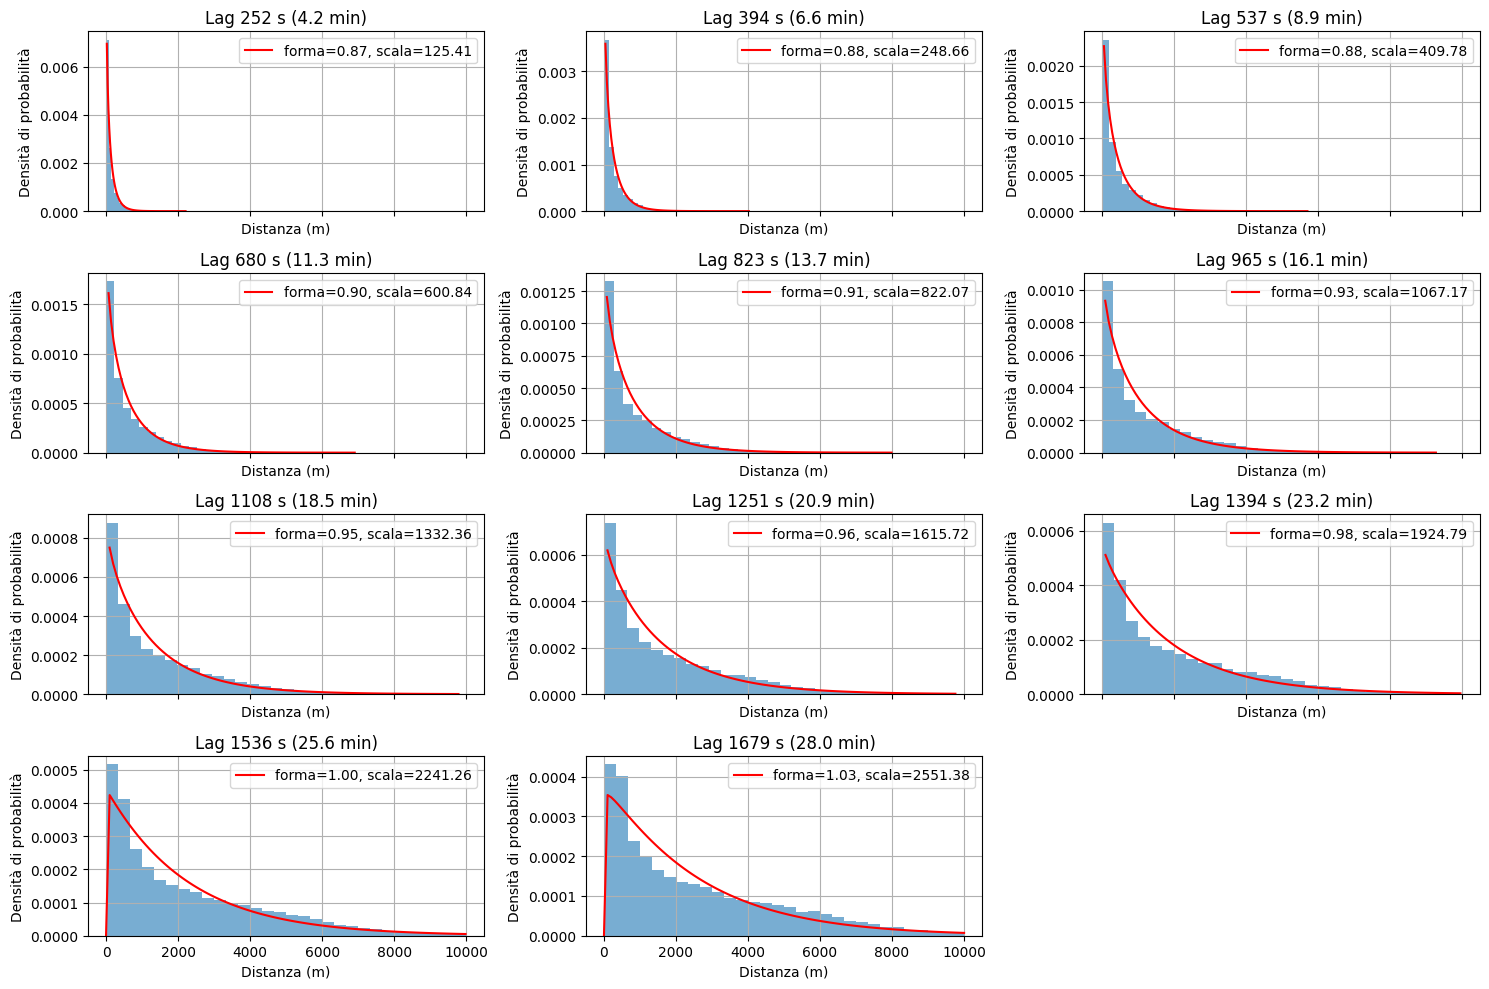


Estimated parameter m: 1.3105366928929885
Average shape parameter (β): 0.9357913823055269


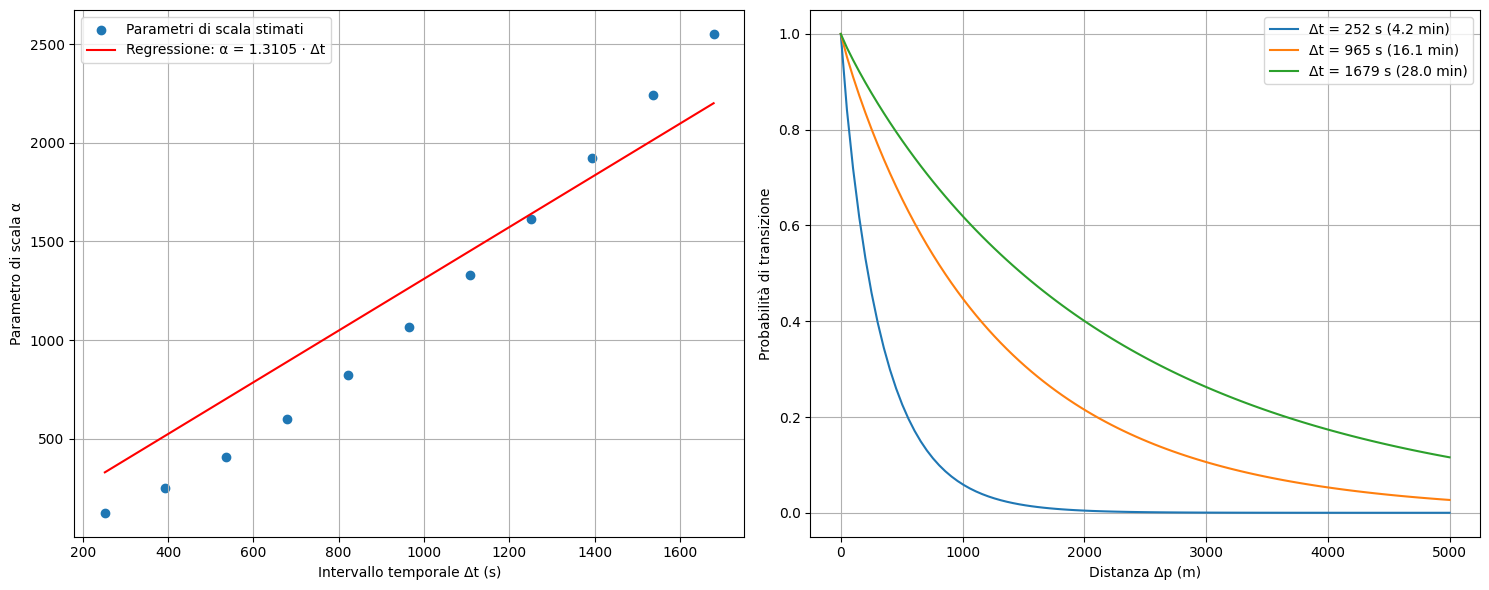


Calculating state sequence probabilities for all trips...
State sequence probability statistics:
  Number of trips processed: 184
  Mean: -0.2950
  Min: -0.7834
  Max: -0.1220
  Std Dev: 0.0965

Calculating combined probabilities for all trips...
Combined probability statistics:
  Number of trips: 184
  Mean: 1994.3932
  Min: 211.3864
  Max: 3134.0474
  Std Dev: 458.4481


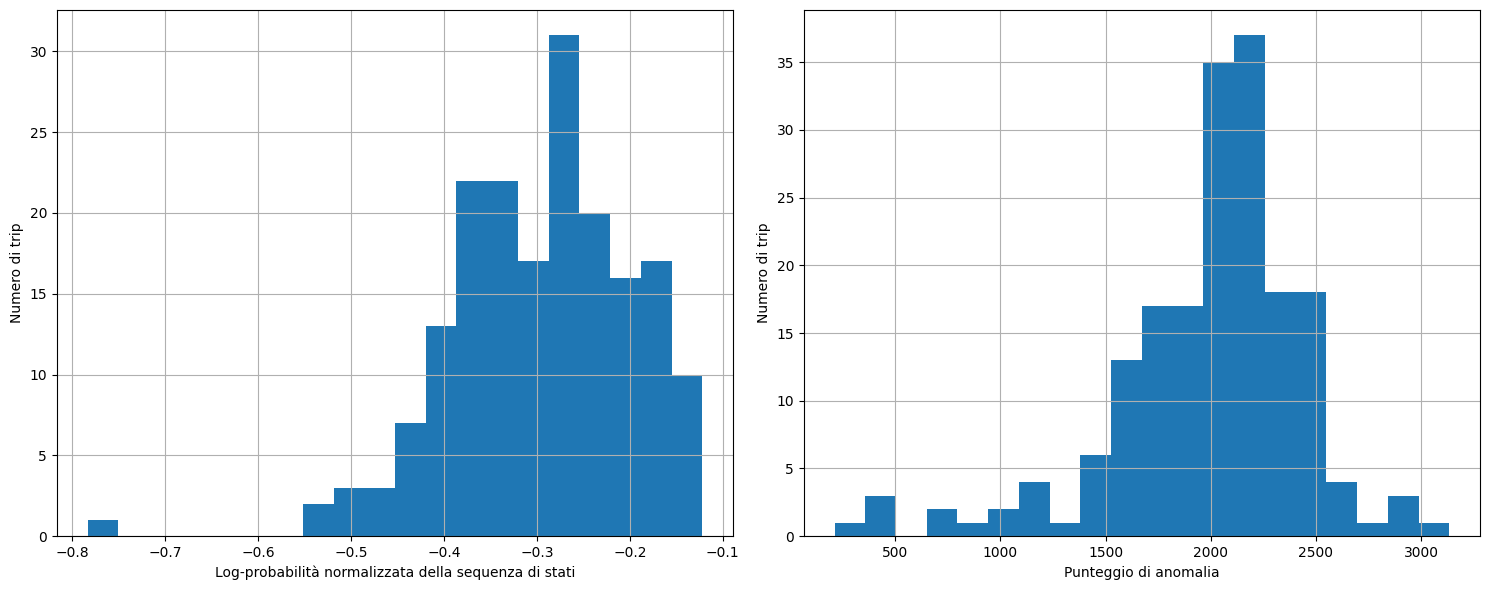

[(np.float64(3134.047357385602), 23184),
 (np.float64(2965.5142497424276), 24337),
 (np.float64(2952.936185705164), 23474),
 (np.float64(2856.186396149262), 8857),
 (np.float64(2724.763601598397), 11128),
 (np.float64(2651.543489566744), 14569),
 (np.float64(2618.937539167177), 8374),
 (np.float64(2596.3383721788855), 15733),
 (np.float64(2577.4679586256384), 25609),
 (np.float64(2534.984162200531), 11307),
 (np.float64(2532.134806350404), 25652),
 (np.float64(2523.991658750206), 22522),
 (np.float64(2513.7594151205185), 17090),
 (np.float64(2507.2215236875227), 11867),
 (np.float64(2494.306920280133), 26303),
 (np.float64(2491.6839571365344), 34662),
 (np.float64(2491.6145951428807), 25676),
 (np.float64(2489.225598575002), 1621),
 (np.float64(2469.1151379969783), 16293),
 (np.float64(2455.830243543164), 6085),
 (np.float64(2445.7555465784653), 213),
 (np.float64(2433.1228328605284), 6125),
 (np.float64(2426.302182466794), 11374),
 (np.float64(2423.136690631326), 18288),
 (np.float64(


Top 10 trips by combined probability:
  Trip 23184: 3134.0474
  Trip 24337: 2965.5142
  Trip 23474: 2952.9362
  Trip 8857: 2856.1864
  Trip 11128: 2724.7636
  Trip 14569: 2651.5435
  Trip 8374: 2618.9375
  Trip 15733: 2596.3384
  Trip 25609: 2577.4680
  Trip 11307: 2534.9842

Bottom 10 trips by combined probability:
  Trip 28433: 1196.2061
  Trip 30752: 1014.6508
  Trip 7889: 942.0893
  Trip 24701: 814.7078
  Trip 10279: 733.1602
  Trip 30627: 712.3246
  Trip 10288: 468.3232
  Trip 3362: 420.8128
  Trip 3413: 385.9575
  Trip 3372: 211.3864


In [18]:
# Estimate Weibull parameters for each time interval
# This implements the Weibull model described in page 2237, equation (10)
scale_params = []
shape_params = []
valid_lags = []
weibull_data = []  # Store data for later plotting

for i, dist_array in enumerate(distances_arrays):
    lag = time_lags_seconds[i]
    
    # Filter invalid values
    dist_array = dist_array[~np.isnan(dist_array)] # save all the values that are not NaNs
    
    # Filter values that are too large or too negative (should not change anything)
    dist_array = dist_array[(dist_array > 0) & (dist_array < 10000)]
    
    if len(dist_array) < 10:
        print(f"Too few data to estimate Weibull parameters for lag {lag} sec")
        continue
    
    # Use all valid data points for Weibull parameter estimation
    try:
        shape, loc, scale = weibull_min.fit(dist_array, floc=0)
        scale_params.append(scale)
        shape_params.append(shape)
        valid_lags.append(lag)
        print(f"Lag {lag} sec: Estimated shape={shape:.4f}, scale={scale:.4f}")
        
        # Store data for later plotting
        weibull_data.append({
            'lag': lag,
            'data': dist_array,
            'shape': shape,
            'scale': scale
        })
        
    except Exception as e:
        print(f"Error in Weibull fit for lag {lag} sec: {e}")

# Plot Weibull fits in subplots (thanks ChatGPT)
if weibull_data:
    n_fits = len(weibull_data)
    n_cols = min(3, n_fits)
    n_rows = (n_fits + n_cols - 1) // n_cols
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 10), sharex=True)
    if n_rows * n_cols > 1:
        axes = axes.flatten()
    else:
        axes = [axes]
    
    for i, data in enumerate(weibull_data):
        if i < len(axes):
            lag = data['lag']
            dist_array = data['data']
            shape = data['shape']
            scale = data['scale']
            
            axes[i].hist(dist_array, bins=30, density=True, alpha=0.6)
            x = np.linspace(0, np.max(dist_array), 100)
            pdf = weibull_min.pdf(x, shape, loc=0, scale=scale)
            axes[i].plot(x, pdf, 'r-', label=f'forma={shape:.2f}, scala={scale:.2f}')
            axes[i].set_title(f'Lag {lag} s ({lag/60:.1f} min)')
            axes[i].set_xlabel('Distanza (m)')
            axes[i].set_ylabel('Densità di probabilità')
            axes[i].legend()
            axes[i].grid(True)
    
    # Hide unused subplots
    for i in range(n_fits, len(axes)):
        axes[i].axis('off')
        
    plt.tight_layout()
    # no suptitle: the figure is used in the thesis, where the caption describes it
    plt.show()

# Convert to numpy arrays for regression
valid_lags = np.array(valid_lags)
scale_params = np.array(scale_params)
shape_params = np.array(shape_params)

if len(valid_lags) < 2:
    print("Insufficient data for linear regression")
else:
    # Estimate parameter m with linear regression (equation 11: αk = mk·Δt)
    def linear_model(x, m):
        return m * x

    try:
        #popt -> optimal values such that the MSE is minimized
        #pcov -> estimated covariance of popt
        popt, pcov = curve_fit(linear_model, valid_lags, scale_params) # the first param must be a function (callable)
        m = popt[0]
        print(f"\nEstimated parameter m: {m}")
        
        # Average shape parameter (β)
        shape = np.mean(shape_params)
        print(f"Average shape parameter (β): {shape}")
        
        # Create a figure with two subplots
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
        
        # First subplot: Regression line
        ax1.scatter(valid_lags, scale_params, label='Parametri di scala stimati')
        ax1.plot(valid_lags, m * valid_lags, 'r-', label=f'Regressione: α = {m:.4f} · Δt')
        ax1.set_xlabel('Intervallo temporale Δt (s)')
        ax1.set_ylabel('Parametro di scala α')
        ax1.legend()
        ax1.grid(True)
        
        # Second subplot: Transition probabilities
        delta_p_range = np.linspace(0, 5000, 100)  # distances in meters
        
        for lag in [valid_lags[0], valid_lags[len(valid_lags)//2], valid_lags[-1]]:
            # Calculate transition probability according to eq. (14)
            transition_probs = np.exp(-(delta_p_range / (m * lag))**shape)
            ax2.plot(delta_p_range, transition_probs, label=f'Δt = {lag} s ({lag/60:.1f} min)')
        
        ax2.set_xlabel('Distanza Δp (m)')
        ax2.set_ylabel('Probabilità di transizione')
        ax2.legend()
        ax2.grid(True)
        
        plt.tight_layout()
        plt.show()
        
        # Calculate the state sequence probabilities for ALL trips
        # This implements equation (9) on page 2236
        print("\nCalculating state sequence probabilities for all trips...")
        
        # Dictionary to store results 
        trip_state_probs = {}
        
        # for each trip
        for trip_id in all_trip_ids:
            # redundant sort, but better be safe than sorry
            trip_data = train_DF[train_DF['trip_id'] == trip_id].sort_values('BaseDateTime')
            
            if len(trip_data) < c.SHORT_TRIP_THRESHOLD:
                continue
            
            # Calculate P(S|R^k_c) - probability of the state sequence (equation 9)
            log_state_prob = 0
            valid_transitions = 0
            
            for i in range(1, len(trip_data)):
                time_lag = (trip_data.iloc[i]['BaseDateTime'] - trip_data.iloc[i-1]['BaseDateTime']).total_seconds()
                
                if time_lag <= 0: # should never happen, but you'll never know
                    print('ALARM!!! Time Lag <= 0!!!!')
                    continue
                
                prev_point = trip_data.iloc[i-1]
                curr_point = trip_data.iloc[i]

                # Predict the current position from the previous one (Track Predictor, Algorithm 4, page 2237)
                pred_lat, pred_lon = f.predict_position(prev_point['LAT'], prev_point['LON'],
                                                        prev_point['V_x'], prev_point['V_y'], time_lag)
                # Δp: distance in meters between the predicted and the actual position (same definition used for the Weibull fit)
                delta_p = f.great_circle_distance_vectorized(lat_left=curr_point['LAT'], lon_left=curr_point['LON'],
                                                             lat_right=pred_lat, lon_right=pred_lon)

                # Apply equation (14) from page 2237 directly in log form: log(exp(-x^β)) = -x^β.
                # Computing exp() first would underflow to 0 for very unlikely transitions, which would then be
                # skipped and make the most anomalous trips look normal
                log_state_prob += -(delta_p / (m * time_lag))**shape
                valid_transitions += 1
            
            # Normalize by the number of transitions to make trips of different lengths comparable
            # Without normalization, longer trips would have naturally lower log() values because they have more values in the sum
            if valid_transitions > 0:
                log_state_prob = log_state_prob / valid_transitions
            
            trip_state_probs[trip_id] = log_state_prob
        
        # Print summary statistics for the state sequence probabilities
        state_prob_values = np.array(list(trip_state_probs.values()))
        print(f"State sequence probability statistics:")
        print(f"  Number of trips processed: {len(trip_state_probs)}")
        print(f"  Mean: {np.mean(state_prob_values):.4f}")
        print(f"  Min: {np.min(state_prob_values):.4f}")
        print(f"  Max: {np.max(state_prob_values):.4f}")
        print(f"  Std Dev: {np.std(state_prob_values):.4f}")
        
        # Now combine the state sequence probabilities with the observation probabilities
        # This implements the full route classification in equation (4) on page 2235
        print("\nCalculating combined probabilities for all trips...")
        
        # Calculate P(R^k_c) as described in the paper (page 2235)
        # Count the number of distinct vessels for each route
        vessel_route_counts = train_DF.groupby('Route')['MMSI'].nunique()
        total_vessels = train_DF['MMSI'].nunique()
        # Calculate prior probability
        route_priors = vessel_route_counts / total_vessels
        
        # Dictionary to store combined probabilities
        trip_total_probs = {}
        
        for trip_id in all_trip_ids:
            if trip_id not in trip_state_probs:
                continue
            # always sort the valuess
            trip_data = train_DF[train_DF['trip_id'] == trip_id].sort_values('BaseDateTime')
            
            # Get state sequence probability (already calculated)
            log_state_prob = trip_state_probs[trip_id]
            
            # Get the observation probability from the Log_Density_prod column
            # This corresponds to P(V|S̄, R^k_c) from equation (6)
            log_obs_prob = trip_data['Log_Density_prod'].mean()
            
            # Get the route for this trip
            log_prior_prob = 0
            route = trip_data['Route'].iloc[0] # Extract the route from the first point
            # get the prior prob for this route
            if route in route_priors:
                log_prior_prob = np.log(route_priors[route])
            else:
                # ifthe route is not in the priors, use a uniform distribution
                log_prior_prob = np.log(1/len(route_priors)) if len(route_priors) > 0 else 0       
            
            # Calculate total probability (equation 4 after applying equation 5)
            # P(R^k_c|V, S) proportional to P(V|S, R^k_c)P(S|R^k_c)P(R^k_c)
            log_total_prob = log_state_prob + log_obs_prob + log_prior_prob
            # P(R^k_c) empirically calculated
            
            trip_total_probs[trip_id] = log_total_prob
        
        # Print summary statistics for the combined probabilities
        total_prob_values = np.array(list(trip_total_probs.values()))
        print(f"Combined probability statistics:")
        print(f"  Number of trips: {len(trip_total_probs)}")
        print(f"  Mean: {np.mean(total_prob_values):.4f}")
        print(f"  Min: {np.min(total_prob_values):.4f}")
        print(f"  Max: {np.max(total_prob_values):.4f}")
        print(f"  Std Dev: {np.std(total_prob_values):.4f}")
        
        # Plot distributions side by side
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
        
        # State sequence probabilities
        ax1.hist(state_prob_values, bins=20)
        ax1.set_xlabel('Log-probabilità normalizzata della sequenza di stati')
        ax1.set_ylabel('Numero di trip')
        ax1.grid(True)
        
        # Combined probabilities
        ax2.hist(total_prob_values, bins=20)
        ax2.set_xlabel('Punteggio di anomalia')
        ax2.set_ylabel('Numero di trip')
        # no titles: the figure is used in the thesis, where the caption describes it
        ax2.grid(True)
        
        plt.tight_layout()
        plt.show()
        
        
        # Invert probability with 
        sorted_items = [(prob, dest) for dest, prob in trip_total_probs.items()]
        sorted_items.sort(reverse=True) # decreasing order
        sorted_total = [(dest, prob) for prob, dest in sorted_items]
        display(sorted_items)
        # Display top 10 and bottom 10 trips by combined probability
        print("\nTop 10 trips by combined probability:")
        for trip_id, prob in sorted_total[:10]:
            print(f"  Trip {trip_id}: {prob:.4f}")
            
        print("\nBottom 10 trips by combined probability:")
        for trip_id, prob in sorted_total[-10:]:
            print(f"  Trip {trip_id}: {prob:.4f}")
        
        # Prepare data for geographic visualization
        # First, extract the trips with highest and lowest probabilities for visualization
        best_trip_id = sorted_total[0][0]
        worst_trip_id = sorted_total[-1][0]
        
        # Function to create a plotly map for a trip
        def create_trip_map(trip_id, title_suffix=""):
            trip_data = train_DF[train_DF['trip_id'] == trip_id].sort_values('BaseDateTime')
            
            # Create scatter mapbox for the trip points
            fig = px.scatter_map(
                trip_data,
                lat="LAT",
                lon="LON",
                color="Avg_Speed",  # Color by speed over ground
                size_max=15,
                zoom=8,
                map_style=f._BASEMAP_STYLE,
                title=f"Trip {trip_id} {title_suffix}",
                hover_data=["MMSI", "BaseDateTime", "SOG", "COG"],
                color_continuous_scale='portland',
                labels=f._COLORBAR_TITLES
            )
            
            fig.update_layout(
                margin={"r": 40, "t": 40, "l": 40, "b": 40},
                showlegend=True
            )
            
            return fig
        
        # Create maps for best and worst trips
        best_trip_map = create_trip_map(best_trip_id, "(Highest Probability)")
        worst_trip_map = create_trip_map(worst_trip_id, "(Lowest Probability)")
        
        # Save the maps to HTML files and open them in the browser
        pyo.plot(best_trip_map, filename='../../plot/best_trip_map.html', auto_open=True)
        pyo.plot(worst_trip_map, filename='../../plot/worst_trip_map.html', auto_open=True)
        
        # Create a map with multiple trips colored by probability
        # Select a sample of trips for visualization (too many would clutter the map)
        sample_trips = sorted_total[:5] + sorted_total[-5:]  # Top 5 and bottom 5
        
        # Prepare data for the combined map
        all_trips_data = []
        
        for trip_id, prob in sample_trips:
            trip_data = train_DF[train_DF['trip_id'] == trip_id].sort_values('BaseDateTime')
            trip_data = trip_data.copy()
            trip_data['log_prob'] = prob  # Add probability to the data
            all_trips_data.append(trip_data)
        
        combined_data = pd.concat(all_trips_data)
        
        # Create the combined map
        fig = px.scatter_map(
            combined_data,
            lat="LAT",
            lon="LON",
            color="log_prob",  # Color by probability
            color_continuous_scale="portland",
            size_max=10,
            zoom=7,
            map_style=f._BASEMAP_STYLE,
            hover_data=["MMSI", "trip_id", "BaseDateTime", "log_prob"],
            labels=f._COLORBAR_TITLES
        )
        
        # Improve layout
        # no title: the map is used in the thesis, where the caption describes it
        fig.update_layout(
            margin={"r": 0, "t": 0, "l": 0, "b": 0},
            showlegend=True
        )
        
        # Save to HTML file and open in browser
        f._save_map(fig, 'multiple_trips_map.html') # with the scale bar
        
        
        # Group by route
        route_colors = {}
        color_scale = px.colors.qualitative.Plotly
        
        for i, route in enumerate(train_DF['Route'].unique()):
            route_colors[route] = color_scale[i % len(color_scale)]
        
        # Create a figure with all trips colored by route
        fig = go.Figure()
        
        # Add traces for each route
        for route in train_DF['Route'].unique():
            # Filter for this route
            route_data = train_DF[train_DF['Route'] == route]
            
            # Get unique trips for this route
            route_trips = route_data['trip_id'].unique()
            
            # For each trip, add a separate trace
            for trip_id in route_trips[:10]:  # Limit to 3 trips per route to avoid clutter
                trip_data = route_data[route_data['trip_id'] == trip_id].sort_values('BaseDateTime')
                
                # Add scatter points
                fig.add_trace(
                    go.Scattermap(
                        lat=trip_data["LAT"],
                        lon=trip_data["LON"],
                        mode="markers+lines",
                        marker=dict(size=8, color=route_colors[route]),
                        line=dict(width=2, color=route_colors[route]),
                        name=f"Route: {route}, Trip: {trip_id}",
                        hoverinfo="text",
                        hovertext=[
                            f"Route: {route}<br>Trip: {trip_id}<br>MMSI: {row['MMSI']}<br>Time: {row['BaseDateTime']}"
                            for _, row in trip_data.iterrows()
                        ]
                    )
                )
        
        # Update layout
        fig.update_layout(
            map=dict(
            style=f._BASEMAP_STYLE,
            center=dict(
                    lat=train_DF["LAT"].mean(),
                    lon=train_DF["LON"].mean()
                ),
                zoom=7
            ),
            margin={"r": 40, "t": 40, "l": 40, "b": 40},
            title="Trips Colored by Route"
        )
        
        # Save to HTML file and open in browser
        pyo.plot(fig, filename='../../plot/trips_by_route_map.html', auto_open=True)
        
        # Create a map showing the probability assessment for one specific route
        # Select a route that has multiple trips
        route_trip_counts = train_DF.groupby('Route')['trip_id'].nunique()
        selected_route = route_trip_counts.idxmax()  # Route with most trips
        
        # Get trips for this route
        route_data = train_DF[train_DF['Route'] == selected_route]
        route_trips = route_data['trip_id'].unique()
        
        # Prepare data with probabilities
        route_trip_data = []
        
        for trip_id in route_trips:
            if trip_id in trip_total_probs:
                trip_data = route_data[route_data['trip_id'] == trip_id].sort_values('BaseDateTime')
                trip_data = trip_data.copy()
                trip_data['log_prob'] = trip_total_probs[trip_id]
                route_trip_data.append(trip_data)
        
        if route_trip_data:
            route_combined_data = pd.concat(route_trip_data)
            
            # Create the map
            fig = px.scatter_map(
                route_combined_data,
                lat="LAT",
                lon="LON",
                color="log_prob",
                color_continuous_scale="portland",
                size_max=10,
                zoom=8,
                map_style=f._BASEMAP_STYLE,
                title=f"Trips for Route '{selected_route}' colored by probability",
                hover_data=["MMSI", "trip_id", "BaseDateTime", "log_prob"],
                labels=f._COLORBAR_TITLES
            )
            
            # Improve layout
            fig.update_layout(
                margin={'r':40, 't':40, 'l':40, 'b':40},
                showlegend=True
            )
            
            # Save to HTML file and open in browser
            pyo.plot(fig, filename='../../plot/route_probability_map.html', auto_open=True)
        
    except Exception as e:
        print(f"Error in regression or probability calculation: {e}")

Manual labelling of the trips (ground truth for the confusion matrix)

In [19]:
# Opens plot/trip_labeling.html: one trip at a time, in random order, without trip_id and score.
# At the end, "Scarica CSV" downloads trip_labels.csv (trip_id,label with 1 = anomalous): move it to out/
f.labeling_tool(train_DF)

Evaluation metrics against the manual labels (out/trip_labels.csv): case A = all anomalies, case B = route deviations only

Trip con punteggio ed etichetta: 184 (etichette: 184, punteggi: 184)
Normali: 143, route deviation: 21, altre anomalie: 20
Soglia (Q1 - 1,5 IQR): 1035.48  (Q1 = 1760.74, Q3 = 2244.25)

Caso A - Tutte le anomalie: 184 trip, 41 anomali
  TN = 143, FP = 0, FN = 32, TP = 9
  Accuracy:  0.826
  Precision: 1.000
  Recall:    0.220
  F1:        0.360
  AUC:       0.751
  Falsi positivi (0): []
  Falsi negativi (32): [34378, 23085, 22218, 5650, 11362, 8148, 23445, 24062, 23388, 24562, 24594, 11277, 34437, 5482, 23017, 16714, 22452, 8127, 24737, 16616, 23892, 23538, 11353, 10583, 3452, 23889, 21675, 25652, 25609, 8374, 8857, 23474]

Caso B - Solo route deviation: 164 trip, 21 anomali
  TN = 143, FP = 0, FN = 12, TP = 9
  Accuracy:  0.927
  Precision: 1.000
  Recall:    0.429
  F1:        0.600
  AUC:       0.844
  Falsi positivi (0): []
  Falsi negativi (12): [34378, 5650, 11362, 11277, 34437, 5482, 16714, 16616, 11353, 10583, 23889, 25652]


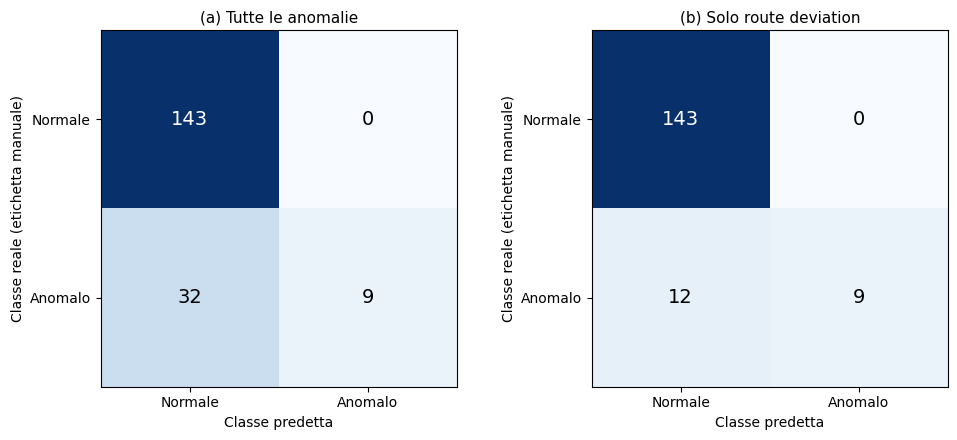

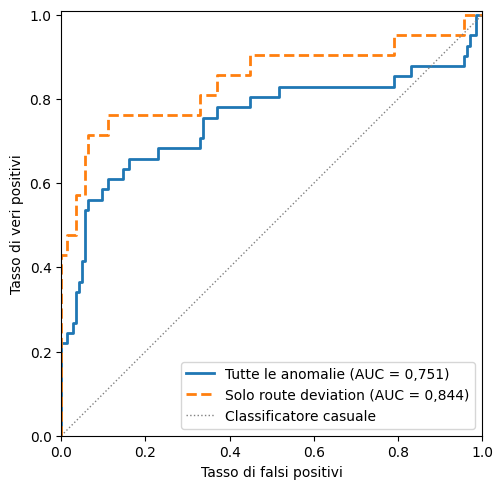

Gtk-Message: 00:09:46.943: Not loading module "atk-bridge": The functionality is provided by GTK natively. Please try to not load it.
Gtk-Message: 00:09:46.978: Not loading module "atk-bridge": The functionality is provided by GTK natively. Please try to not load it.
Gtk-Message: 00:09:47.070: Not loading module "atk-bridge": The functionality is provided by GTK natively. Please try to not load it.
Gtk-Message: 00:09:47.192: Not loading module "atk-bridge": The functionality is provided by GTK natively. Please try to not load it.
Gtk-Message: 00:09:48.094: Not loading module "atk-bridge": The functionality is provided by GTK natively. Please try to not load it.
Gtk-Message: 00:09:48.284: Not loading module "atk-bridge": The functionality is provided by GTK natively. Please try to not load it.


In [20]:
# Evaluation against the manual labels (used ONLY as ground truth for the metrics: the method is unsupervised)
# out/trip_labels.csv: 0 = normal, 1 = route deviation, 2 = other anomaly (e.g. the trip ends outside the port)
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, roc_curve, roc_auc_score

labels = pd.read_csv('../../out/trip_labels.csv').set_index('trip_id')['label']
scores = pd.Series(trip_total_probs, name='score')                                 # high score = normal trip
eval_DF = pd.concat([scores, labels], axis=1, join='inner')
print(f"Trip con punteggio ed etichetta: {len(eval_DF)} (etichette: {len(labels)}, punteggi: {len(scores)})")
print(f"Normali: {(eval_DF['label'] == 0).sum()}, route deviation: {(eval_DF['label'] == 1).sum()}, "
      f"altre anomalie: {(eval_DF['label'] == 2).sum()}")

# Threshold fixed on all the scores and without the labels: lower Tukey fence (Q1 - 1.5 IQR)
q1, q3 = eval_DF['score'].quantile([0.25, 0.75])
threshold = q1 - 1.5 * (q3 - q1)
eval_DF['pred'] = (eval_DF['score'] < threshold).astype(int)
print(f"Soglia (Q1 - 1,5 IQR): {threshold:.2f}  (Q1 = {q1:.2f}, Q3 = {q3:.2f})")

# Case A: every anomaly in a single generic class. Case B: route deviations only, other anomalies excluded
cases = {
    'A': ('Tutte le anomalie', eval_DF.assign(y=(eval_DF['label'] > 0).astype(int))),
    'B': ('Solo route deviation', eval_DF[eval_DF['label'] != 2].assign(y=lambda x: (x['label'] == 1).astype(int))),
}
results = {}
for key, (name, data) in cases.items():
    y, y_pred = data['y'], data['pred']
    cm = confusion_matrix(y, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    fpr, tpr, _ = roc_curve(y, -data['score'])     # anomaly score = -score (low score = anomalous)
    auc = roc_auc_score(y, -data['score'])
    results[key] = dict(cm=cm, fpr=fpr, tpr=tpr, auc=auc)
    print(f"\nCaso {key} - {name}: {len(data)} trip, {y.sum()} anomali")
    print(f"  TN = {tn}, FP = {fp}, FN = {fn}, TP = {tp}")
    print(f"  Accuracy:  {(tp + tn) / len(y):.3f}")
    print(f"  Precision: {precision_score(y, y_pred, zero_division=0):.3f}")
    print(f"  Recall:    {recall_score(y, y_pred, zero_division=0):.3f}")
    print(f"  F1:        {f1_score(y, y_pred, zero_division=0):.3f}")
    print(f"  AUC:       {auc:.3f}")
    false_pos = data[(y_pred == 1) & (y == 0)].sort_values('score')
    false_neg = data[(y_pred == 0) & (y == 1)].sort_values('score')
    print(f"  Falsi positivi ({len(false_pos)}): {false_pos.index.tolist()}")
    print(f"  Falsi negativi ({len(false_neg)}): {false_neg.index.tolist()}")

# Figure 1: confusion matrices of the two cases
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, (key, (name, _)) in zip(axes, cases.items()):
    cm = results[key]['cm']
    ax.imshow(cm, cmap='Blues')
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=14,
                    color='white' if cm[i, j] > cm.max() / 2 else 'black')
    ax.set_xticks([0, 1], ['Normale', 'Anomalo'])
    ax.set_yticks([0, 1], ['Normale', 'Anomalo'])
    ax.set_xlabel('Classe predetta')
    ax.set_ylabel('Classe reale (etichetta manuale)')
    ax.set_title(f'({key.lower()}) {name}', fontsize=11)   # panel label, the description is in the caption
plt.tight_layout()
plt.show()

# Figure 2: ROC curves of the two cases
fig, ax = plt.subplots(figsize=(5.5, 5))
for (key, (name, _)), style in zip(cases.items(), ['-', '--']):
    r = results[key]
    ax.plot(r['fpr'], r['tpr'], linestyle=style, linewidth=2,
            label=f"{name} (AUC = {r['auc']:.3f})".replace('.', ','))
ax.plot([0, 1], [0, 1], linestyle=':', color='grey', linewidth=1, label='Classificatore casuale')
ax.set_xlabel('Tasso di falsi positivi')
ax.set_ylabel('Tasso di veri positivi')
ax.set_xlim(0, 1); ax.set_ylim(0, 1.01)
ax.set_aspect('equal')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()